In [1]:
import numpy as np
import scipy
import matplotlib.pyplot as plt

## Rejection sampling

In [2]:
def g2(s):
    if s<0:
        return 0.5*s+1
    else:
        return -0.5*s + 1
    
def g3(s):
    
    return 1/4
    

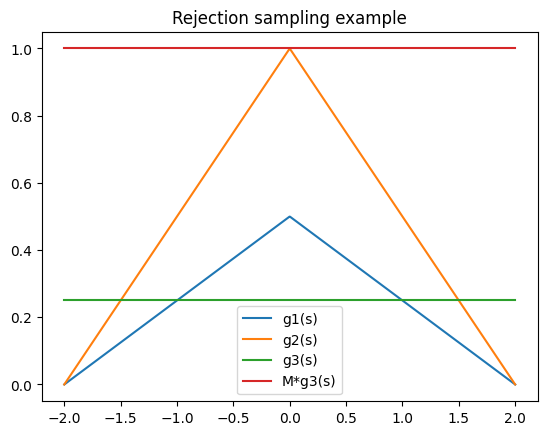

In [3]:
m = 4
x_vals = np.linspace(-2,2,1000)

y_vals = []
norm_vals = []
for x_val in x_vals:
    y_vals.append(g2(x_val))
    norm_vals.append(m*g3(x_val))
    
plt.figure()
plt.title('Rejection sampling example')
plt.plot(x_vals, np.array(y_vals)/2, label = 'g1(s)')
plt.plot(x_vals, y_vals, label = 'g2(s)')
plt.plot(x_vals, np.array(norm_vals)*(1/4), label = 'g3(s)')
plt.plot(x_vals, norm_vals, label = 'M*g3(s)')
plt.legend()
plt.savefig('rejection.png')
plt.show()


In [6]:
samples = []
for ind in range(50000):
    s = np.random.uniform(-2,2)
    prob_accepct = g2(s)/(m*g3(s))
    if np.random.rand()<prob_accepct:
        samples.append(s)
        
        
len(samples)/50000

0.49826

### Ploting the samples histogram against the true density

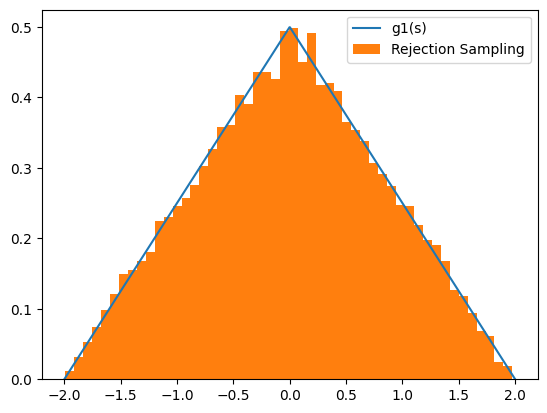

In [5]:


plt.figure()
plt.plot(x_vals, np.array(y_vals)/2, label = 'g1(s)')
plt.hist(samples, density = True, bins = 50, label = 'Rejection Sampling')
plt.legend()
plt.show()


### Metropolis Hasting 

Suppose we wish to sample from the following distributuin p(x):
$$ p(x) =  \frac{\lambda^n x^{k-1} e^{-\lambda x}}{(k-1)!}  $$

However, we do not hold the true distirbution of p(x), instead we have f(x). 

$$ f(x) =  x^{k-1} e^{-\lambda x}$$

Which means:

$$ p(x) = \frac{f(x)}{NC}, $$

where NC is a normalizing constant.

For the sake of demonstration, suppose $\lambda = 5$ and $k=5$ 

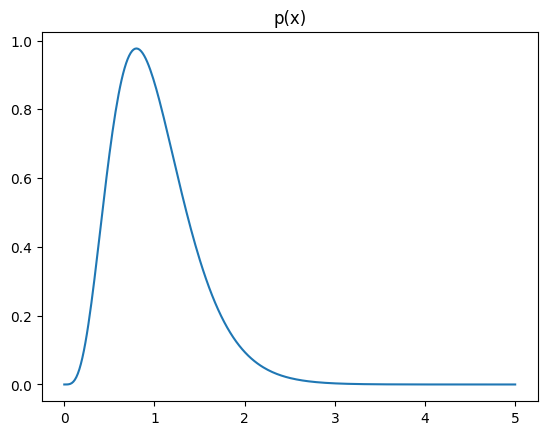

In [375]:
import math
## The true distribution of p(x) looks like:
lam = 5
k = 5

x_vals = np.linspace(0,5,300)

y_vals_p = (lam**5)*(x_vals**(k-1))*(np.exp(-lam*x_vals))/(math.factorial(k-1))
# y_vals_f = (x_vals**(k-1))*(np.exp(-lam*x_vals))

plt.figure()

plt.plot(x_vals, y_vals_p)
plt.title('p(x)')
plt.show()

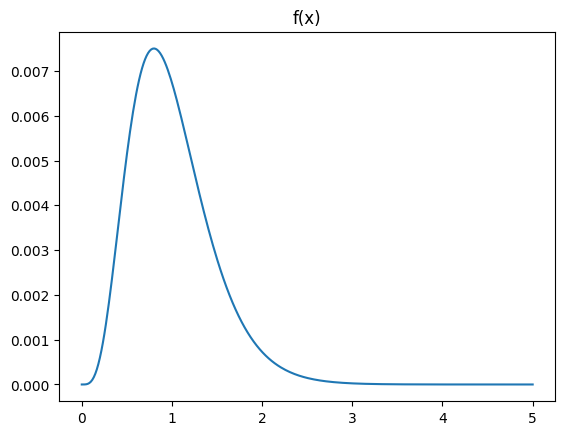

In [376]:
import math
## The true distribution of p(x) looks like:
lam = 5
k = 5

x_vals = np.linspace(0,5,300)

y_vals_f = (x_vals**(k-1))*(np.exp(-lam*x_vals))

plt.figure()
plt.plot(x_vals, y_vals_f)
plt.title('f(x)')
plt.show()

We next propose a distribtuion that is easy to sample from on the same domain: exponential
$$ g(x_{t+1}|x_t)\sim exp(1/x_t) $$

In [377]:
from tqdm import tqdm
num_trials = 90000
x_prev = 1 

samples = []

for trial in tqdm(range(num_trials)):
    
    # Proposing the next distribution with man value x_prev
    x_next = np.random.exponential(x_prev)
    
    # extracing the parameter of the exponential distribution: 1/mean
    lam_next = 1/x_next
    lam_prev = 1/x_prev
    
    # Computing the f() values for the current and next step
    f_next = (x_next**(k-1))*(np.exp(-lam*x_next))
    f_prev = (x_prev**(k-1))*(np.exp(-lam*x_prev))
    
    # computing r_f
    r_f =f_next/f_prev
    
    # computing g(a|b)
    g_next = (lam_prev)*np.exp(-(lam_prev)*x_next)
    g_prev = (lam_next)*np.exp(-(lam_next)*x_prev)
    
    # computing r_g
    r_g = g_prev/g_next
    
    # computing acceptence probability
    accept_prob = min(1, r_f*r_g)
    
    # if we accept
    if accept_prob > np.random.rand():
        samples.append(x_next)
        x_prev = x_next
    else:  # if we reject
        samples.append(x_prev)


100%|████████████████████████████████████████████████████████████████████████| 90000/90000 [00:00<00:00, 102480.56it/s]


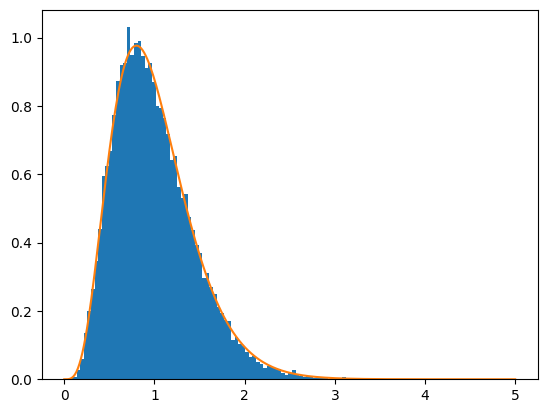

In [378]:
plt.figure()
plt.hist(samples[5000:], bins = 100, density = True)
plt.plot(x_vals, y_vals_p)
plt.show()

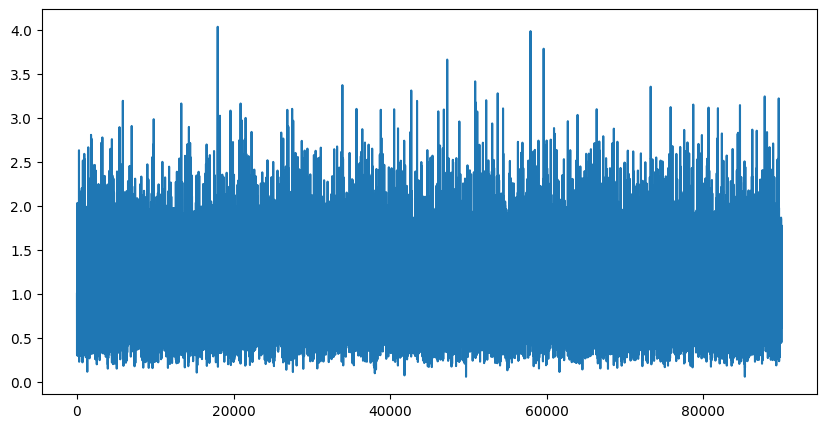

In [379]:
plt.figure(figsize=(10,5))
plt.plot(np.arange(len(samples)),samples )
plt.show()

In [20]:
scipy.stats.norm(0, 1).pdf(x)

array([0.02665214, 0.0296985 , 0.03302004, 0.03663206, 0.04054955,
       0.04478694, 0.049358  , 0.05427559, 0.05955143, 0.06519596,
       0.07121803, 0.0776247 , 0.08442105, 0.09160987, 0.09919153,
       0.1071637 , 0.11552116, 0.12425566, 0.13335569, 0.14280642,
       0.1525895 , 0.16268307, 0.17306164, 0.18369615, 0.19455396,
       0.20559893, 0.21679157, 0.22808919, 0.23944611, 0.25081392,
       0.26214179, 0.2733768 , 0.28446433, 0.29534848, 0.30597253,
       0.3162794 , 0.32621215, 0.33571453, 0.34473146, 0.35320956,
       0.36109774, 0.3683476 , 0.37491403, 0.38075561, 0.38583507,
       0.39011967, 0.39358159, 0.39619817, 0.39795222, 0.39883215,
       0.39883215, 0.39795222, 0.39619817, 0.39358159, 0.39011967,
       0.38583507, 0.38075561, 0.37491403, 0.3683476 , 0.36109774,
       0.35320956, 0.34473146, 0.33571453, 0.32621215, 0.3162794 ,
       0.30597253, 0.29534848, 0.28446433, 0.2733768 , 0.26214179,
       0.25081392, 0.23944611, 0.22808919, 0.21679157, 0.20559

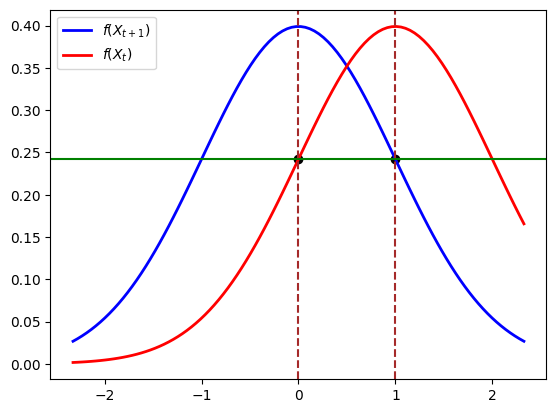

In [37]:
import numpy as np
from scipy.stats import norm
import matplotlib.pyplot as plt
plt.figure()
x = np.linspace(norm.ppf(0.01),
                norm.ppf(0.99), 100)


rv = norm()
plt.plot(x, scipy.stats.norm(0, 1).pdf(x), 'b-', lw=2, label='$f(X_{t+1})$')

plt.plot(x, scipy.stats.norm(1, 1).pdf(x), 'r-', lw=2, label='$f(X_{t})$')
plt.scatter(0, scipy.stats.norm(1, 1).pdf(0), color = 'black')
plt.scatter(1, scipy.stats.norm(0, 1).pdf(1), color = 'black')
plt.axhline(y=scipy.stats.norm(1, 1).pdf(0), color='g', linestyle='-')
plt.axvline(x=0, color='brown', linestyle='dashed')
plt.axvline(x=1, color='brown', linestyle='dashed')
plt.legend()


plt.show()